# NumCompute-Stream demo
A decision-tree based **streaming** ML framework built only on NumPy + matplotlib.

This notebook:
1. loads a CSV through our own I/O pipeline (`numcompute_stream.io`),
2. splits it into chunks to simulate a data stream,
3. trains a `Pipeline(Imputer -> StandardScaler -> DecisionTreeClassifier)` incrementally with `.partial_fit()`,
4. logs and visualises accuracy, retrain events, memory and timings with `visualise.py`,
5. compares two `buffer_size` settings.

The data contains **missing values** and a **concept drift** half way through the stream (the informative features change), so you can watch accuracy dip and recover after the next retrain.

In [1]:
import logging, os, sys
sys.path.insert(0, os.path.abspath(".."))          # repo root, so `numcompute_stream` imports without installing
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

from numcompute_stream.datasets import make_drift_stream
from numcompute_stream.io import (iter_csv_xy_chunks, load_csv_xy, read_feature_names, write_csv_xy)
from numcompute_stream.stats import StreamStats
from numcompute_stream.preprocessing import Imputer, StandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.metrics import Accuracy, F1, ConfusionMatrix
from numcompute_stream.stream import StreamTrainer
from numcompute_stream import visualise as vis

# Per-chunk log lines (INFO) are emitted by the StreamTrainer through the standard logging module.
log = logging.getLogger("numcompute_stream")
_h = logging.StreamHandler(sys.stdout)
_h.setFormatter(logging.Formatter("%(message)s"))
log.addHandler(_h)
log.propagate = False
log.setLevel(logging.WARNING)
os.makedirs("figures", exist_ok=True)
print("setup ok")

setup ok


## 1. Dataset (CSV) and custom I/O pipeline

In [2]:
CSV = "stream_data.csv"
if not os.path.exists(CSV):                         # created once, committed with the repo for reproducibility
    X_all, y_all = make_drift_stream(n_samples=8000, n_features=6, n_classes=3, label_noise=0.03,
                                     drift_at=0.5, missing_rate=0.02, seed=42)
    write_csv_xy(CSV, X_all, y_all)
print("features:", read_feature_names(CSV))
X_peek, y_peek = load_csv_xy(CSV)
print("rows:", X_peek.shape[0], "| classes:", np.unique(y_peek), "| missing cells: %.1f%%" % (100 * np.isnan(X_peek).mean()))

features: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5']
rows: 8000 | classes: [0 1 2] | missing cells: 2.0%


## 2. One-pass streaming statistics (`StreamStats.update_stats`)
The whole file is profiled chunk by chunk with O(features) memory.

In [3]:
CHUNK = 200
stats = StreamStats(reservoir_size=2000, n_bins=15, seed=0)
for X_chunk, y_chunk in iter_csv_xy_chunks(CSV, CHUNK):
    stats.update_stats(X_chunk)
s = stats.summary()
for name in ("count", "mean", "std", "median"):
    print(f"{name:>6}:", np.round(s[name], 3))
print("matches batch mean:", np.allclose(stats.mean, np.nanmean(X_peek, axis=0)))

 count: [7830. 7833. 7857. 7850. 7829. 7844.]
  mean: [ 0.005  0.009 -0.017  0.007 -0.     0.006]
   std: [1.01  1.017 0.997 1.009 0.979 1.003]
median: [-0.01  -0.062  0.005 -0.019 -0.014 -0.024]
matches batch mean: True


## 3. Build the streaming pipeline
`buffer_size=500`: each `partial_fit` adds a chunk to the buffer; when it holds >= 500 samples the tree is retrained on the buffer and the buffer is cleared. Between retrains `predict` uses the last trained tree.

In [4]:
def make_pipeline(buffer_size):
    return Pipeline([
        ("impute", Imputer(strategy="mean")),
        ("scale", StandardScaler()),
        ("model", DecisionTreeClassifier(max_depth=8, buffer_size=buffer_size, random_state=0)),
    ])

trainer = StreamTrainer(make_pipeline(500),
                        metrics={"rolling_accuracy": Accuracy(window=5), "macro_f1": F1(average="macro"),
                                 "confusion": ConfusionMatrix()},
                        name="tree-500")
print(trainer.model)

Pipeline(steps=[('impute', Imputer(fill_value=0.0, missing_values=nan, reservoir_size=5000, strategy='mean')), ('scale', StandardScaler(momentum=None, with_mean=True, with_std=True)), ('model', DecisionTreeClassifier(buffer_size=500, criterion='gini', max_depth=8, max_features=None, min_impurity_decrease=0.0, min_samples_leaf=1, min_samples_split=2, random_state=0, vectorised=True))])


## 4. Prequential run with live visualisation
Each chunk is first **scored** by the current model (test), then used for **training**. The plot refreshes every few chunks.

In [5]:
# (a) first 6 chunks with the per-chunk log lines visible (StreamTrainer logs via the logging module)
log.setLevel(logging.INFO)
stream = iter_csv_xy_chunks(CSV, CHUNK)
for _ in range(6):
    X_chunk, y_chunk = next(stream)
    trainer.process_chunk(X_chunk, y_chunk)
log.setLevel(logging.WARNING)

[tree-500] chunk 0: model not trained yet, chunk not scored


[tree-500] chunk 0 fit: n=200 time=0.0006s mem=19.0KiB buffer=200 retrains=0


[tree-500] chunk 1: model not trained yet, chunk not scored


[tree-500] chunk 1 fit: n=200 time=0.0012s mem=30.0KiB buffer=400 retrains=0


[tree-500] chunk 2: model not trained yet, chunk not scored


[tree-500] chunk 2 fit: n=200 time=0.0545s mem=16.1KiB buffer=0 retrains=1


... (2 outputs left out)

[tree-500] chunk 4 score: chunk_acc=0.8300 cumulative_acc=0.8300


[tree-500] chunk 4 fit: n=200 time=0.0011s mem=38.1KiB buffer=400 retrains=1


[tree-500] chunk 5 score: chunk_acc=0.8250 cumulative_acc=0.8283


[tree-500] chunk 5 fit: n=200 time=0.0596s mem=17.7KiB buffer=0 retrains=2


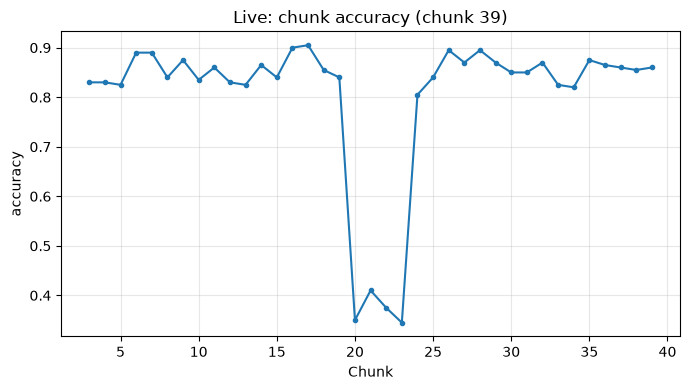

{'n_chunks': 40, 'n_samples': 8000, 'n_scored_chunks': 37, 'n_retrains': 13, 'final_cumulative_accuracy': 0.8032432432432433, 'mean_chunk_accuracy': 0.8032432432432433, 'total_fit_time': 0.6228712000047381, 'total_score_time': 0.01058760000159964, 'max_memory_bytes': 45795}


In [6]:
# (b) remaining chunks with a live-refreshing accuracy plot
last_X = last_y = None
for i, (X_chunk, y_chunk) in enumerate(stream, start=6):
    trainer.process_chunk(X_chunk, y_chunk)
    last_X, last_y = X_chunk, y_chunk
    if i % 8 == 7:
        clear_output(wait=True)
        _ = vis.plot_metric_over_time(trainer.metric_history("chunk_accuracy"),
                                      title=f"Live: chunk accuracy (chunk {i})", ylabel="accuracy")
        plt.show()
print(trainer.summary())

## 5. Logs and visual summary
The log holds, per chunk: accuracy, cumulative accuracy, rolling accuracy, macro-F1, fit time, memory footprint, buffer fill and whether a retrain happened.

In [7]:
for rec in trainer.history[:3] + trainer.history[-2:]:
    keep = ("chunk", "scored", "chunk_accuracy", "cumulative_accuracy", "rolling_accuracy", "macro_f1",
            "fit_time", "memory_bytes", "buffer_fill", "n_retrains", "retrained")
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items() if k in keep})

{'chunk': 0, 'scored': False, 'chunk_accuracy': nan, 'rolling_accuracy': nan, 'macro_f1': nan, 'cumulative_accuracy': nan, 'fit_time': 0.0006, 'memory_bytes': 19479, 'buffer_fill': 200, 'n_retrains': 0, 'retrained': False}
{'chunk': 1, 'scored': False, 'chunk_accuracy': nan, 'rolling_accuracy': nan, 'macro_f1': nan, 'cumulative_accuracy': nan, 'fit_time': 0.0012, 'memory_bytes': 30707, 'buffer_fill': 400, 'n_retrains': 0, 'retrained': False}
{'chunk': 2, 'scored': False, 'chunk_accuracy': nan, 'rolling_accuracy': nan, 'macro_f1': nan, 'cumulative_accuracy': nan, 'fit_time': 0.0545, 'memory_bytes': 16475, 'buffer_fill': 0, 'n_retrains': 1, 'retrained': True}
{'chunk': 38, 'scored': True, 'chunk_accuracy': 0.855, 'rolling_accuracy': 0.855, 'macro_f1': 0.8021, 'cumulative_accuracy': 0.8017, 'fit_time': 0.0506, 'memory_bytes': 17031, 'buffer_fill': 0, 'n_retrains': 13, 'retrained': True}
{'chunk': 39, 'scored': True, 'chunk_accuracy': 0.86, 'rolling_accuracy': 0.863, 'macro_f1': 0.8037, 'c

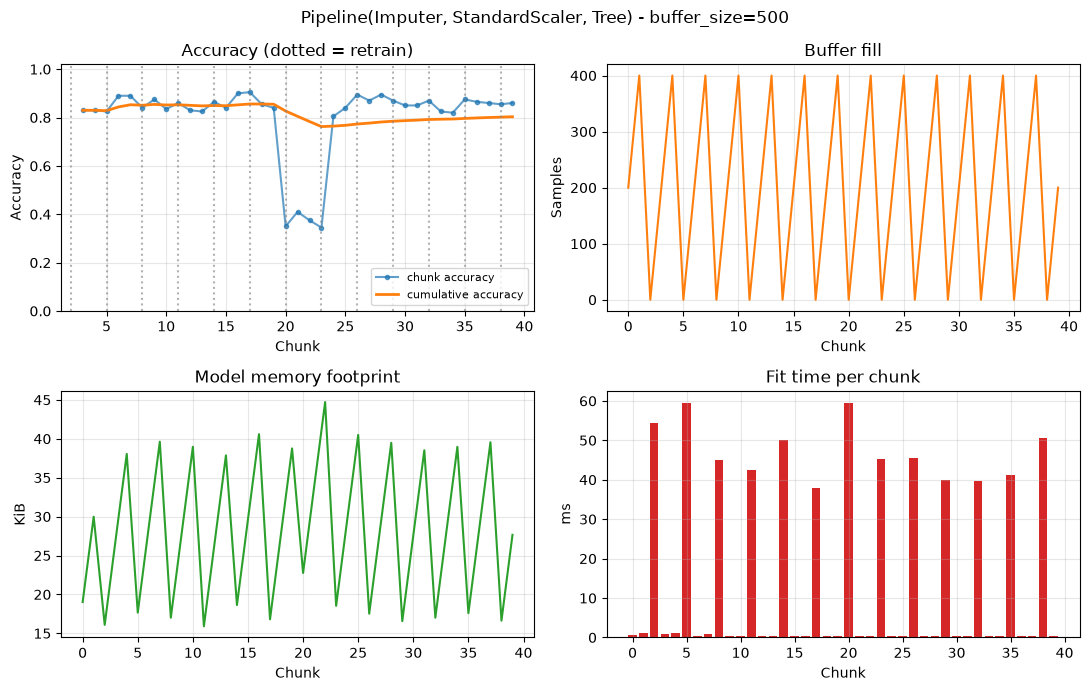

In [8]:
_ = vis.plot_stream_history(trainer.history, title="Pipeline(Imputer, StandardScaler, Tree) - buffer_size=500",
                          save_path="figures/stream_history.png")
plt.show()

## 6. Predictions vs ground truth on the latest chunk

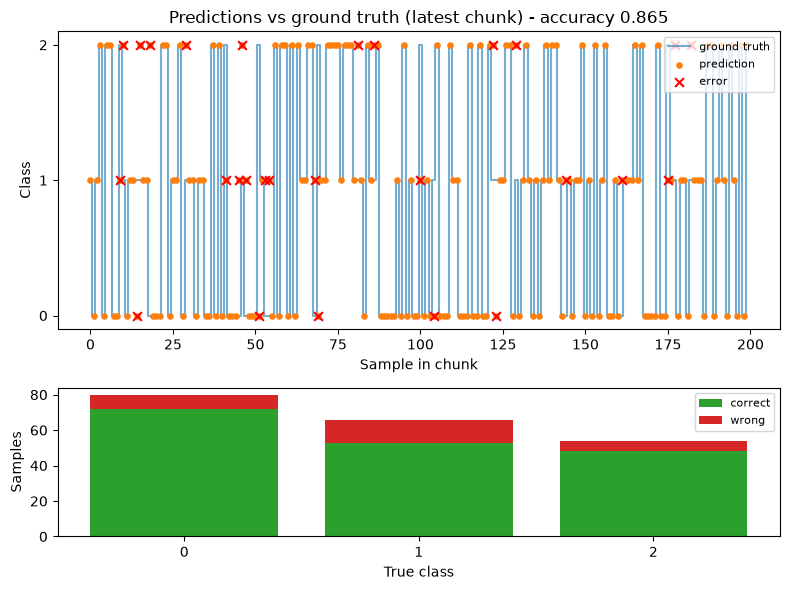

In [9]:
y_hat = trainer.predict(last_X)
_ = vis.plot_predictions_vs_ground_truth(last_y, y_hat, save_path="figures/predictions_vs_truth.png")
plt.show()

## 7. Confusion matrix (accumulated over the stream) and the learned tree

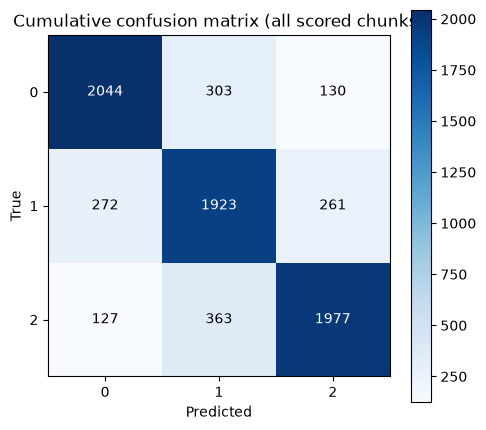

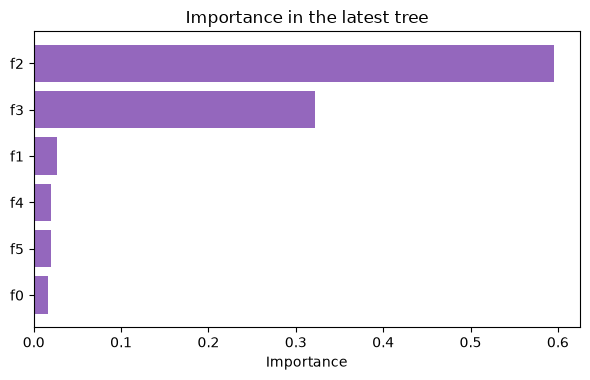

latest tree: depth 8 | leaves 52 | retrains 13
|--- f2 <= 0.4837
|   |--- f2 <= -0.5882
|   |   |--- class: 0
|   |--- f2 >  -0.5882
|   |   |--- class: 1
|--- f2 >  0.4837
|   |--- f3 <= -0.6286
|   |   |--- class: 1
|   |--- f3 >  -0.6286
|   |   |--- class: 2


In [10]:
cm = trainer.metrics["confusion"]
_ = vis.plot_confusion_matrix(cm.result(), labels=cm.labels, title="Cumulative confusion matrix (all scored chunks)",
                             save_path="figures/confusion.png")
plt.show()
tree = trainer.model.final_estimator
names = read_feature_names(CSV)
_ = vis.plot_feature_importance(tree.feature_importances_, names, title="Importance in the latest tree",
                               save_path="figures/importance.png")
plt.show()
print("latest tree: depth", tree.get_depth(), "| leaves", tree.get_n_leaves(), "| retrains", tree.n_retrains_)
print(tree.export_text(feature_names=names, max_depth=2))

## 8. Model comparison: small vs large `buffer_size`
Small buffers adapt faster to drift but each tree sees little data; large buffers learn better on stable data but react later.

buffer_size=  200: accuracy=0.783  retrains= 40  total fit time=1.804s


buffer_size= 2000: accuracy=0.716  retrains=  4  total fit time=0.825s


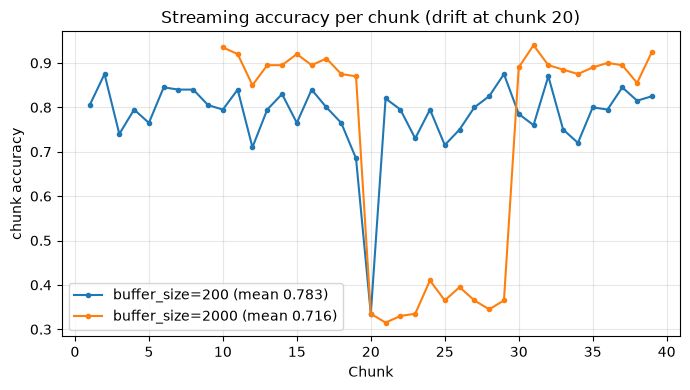

In [11]:
runs = {}
for b in (200, 2000):
    t = StreamTrainer(make_pipeline(b), name=f"tree-{b}")
    t.run(iter_csv_xy_chunks(CSV, CHUNK))
    runs[b] = t
    s = t.summary()
    print(f"buffer_size={b:>5}: accuracy={s['final_cumulative_accuracy']:.3f}  retrains={s['n_retrains']:>3}  "
          f"total fit time={s['total_fit_time']:.3f}s")
_ = vis.compare_models(runs[200].metric_history("chunk_accuracy"), runs[2000].metric_history("chunk_accuracy"),
                      labels=("buffer_size=200", "buffer_size=2000"), title="Streaming accuracy per chunk (drift at chunk 20)",
                      ylabel="chunk accuracy", save_path="figures/compare_buffer_sizes.png")
plt.show()

## 9. Incremental components equal their batch versions
`partial_fit` over chunks gives the same statistics as one batch `fit` (up to floating point).

In [12]:
import numcompute.preprocessing as batch
sc = StandardScaler()
for Xc, _ in iter_csv_xy_chunks(CSV, CHUNK):
    sc.partial_fit(Xc)
ref = batch.StandardScaler().fit(X_peek)
print("StandardScaler mean/scale equal batch:", np.allclose(sc.mean_, ref.mean_), np.allclose(sc.scale_, ref.scale_))

StandardScaler mean/scale equal batch: True True
